## **Context:**

The rapid growth of information has created information overload, making it difficult for consumers to choose products online. Recommender systems address this problem by providing personalized product suggestions that improve user experience and support businesses. Amazon, Walmart, Target, and Etsy invest heavily in recommendation algorithms to enhance the customer experience.

## **Objective:**
As a Data Science Manager at Amazon, your goal is to extract meaningful insights from the data and build a system that recommends products to online consumers.

## **Dataset:**
The Amazon dataset contain the following attributes:

userId: Every user identified with a unique id

productId: Every product identified with a unique id

Rating: The rating of the corresponding product by the corresponding user

timestamp: Time of the rating. We **will not** use this column to solve the current problem

In [ ]:
# Import numpy package to our notebook and check which version is installed. For this project we want to be using version 1.26.0
import numpy as np
print(np.__version__)

In [ ]:
!pip uninstall numpy -y
!pip install numpy==1.26.0

Found existing installation: numpy 1.26.0
Uninstalling numpy-1.26.0:
  Successfully uninstalled numpy-1.26.0
  Using cached numpy-1.26.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (58 kB)
Using cached numpy-1.26.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.9 MB)
ERROR: Operation cancelled by user


In [ ]:
# Install scikit-surprise , an open source (accessible) python library specifically designed for building recommendation systems
!pip install scikit-surprise

In [ ]:
# Import google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import packages that will be used for analysis
import pandas as pd
import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sb

In [ ]:
# Upload data frame
df = pd.read_csv('/content/drive/MyDrive/MIT Course/ratings_Electronics.csv', header=None)

In [ ]:
# Because the dataframe had no column headers/titles, here we name the columns
new_column_names = {0: 'userId', 1: 'productId', 2: 'Rating', 3: 'timestamp'}
df.rename(columns=new_column_names, inplace=True)
display(df.head())

,userId,productId,Rating,timestamp
0,AKM1MP6P0OYPR,0132793040,5.0,1365811200
1,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
2,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
3,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
4,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200


## 'Shaping and Trimming' the Data

For this project, we will be disposing of the timestamp column


In [ ]:
df = df.drop(columns=['timestamp'])

This dataset is very large and has 7,824,482 observations. Since it is difficult to compute and build a model with all these values as we are also dealing with inconsistent data entries- we will reduce the data using logical assumptions.


In [ ]:
# Increasing the rating count if the user has seen the product previously
ratings_count = dict()

for user in df['userId']:
  if user in ratings_count:
    ratings_count[user] += 1
  else:
    ratings_count[user] = 1

In [ ]:
# Users should have rated at least 150 items to be included in the analysis
RATINGS_CUTOFF = 150
remove_users = []

for users, num_ratings in ratings_count.items():
  if num_ratings < RATINGS_CUTOFF:
    remove_users.append(users)

df = df[~df['userId'].isin(remove_users)]

In [ ]:
# Increasing the rating count if the product has been rated previously
products = df.productId

ratings_count = dict()

for products in products:
  if products in ratings_count:
    ratings_count[products] += 1
  else:
    ratings_count[products] = 1

In [ ]:
# Filtering out products that have been rated less than 20 times
RATINGS_CUTOFF = 20

remove_users = []

for user in num_ratings, ratings_count.items():
  if num_ratings < RATINGS_CUTOFF:
    remove_users.append(user)

df = df[~df['productId'].isin(remove_users)]

## 'Travel and Explore' through the data
 Checking the new dataframe values, info, shape, and description

In [ ]:
df.head()

,userId,productId,Rating
178,A17HMM1M7T9PJ1,0970407998,4.0
631,A3TAS1AG6FMBQW,0972683275,5.0
2162,A5JLAU2ARJ0BO,1400532655,1.0
3383,A3PD8JD9L4WEII,1400699169,5.0
4495,A1ZU55TM45Y2R8,8862936826,2.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21960 entries, 178 to 7824444
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     21960 non-null  object 
 1   productId  21960 non-null  object 
 2   Rating     21960 non-null  float64
dtypes: float64(1), object(2)
memory usage: 686.2+ KB


In [ ]:
df.shape

(21960, 3)

In [ ]:
df.dtypes

,0
userId,object
productId,object
Rating,float64


In [ ]:
# Check the data for null values
nulls = df[df.isnull().any(axis=1)]
print(nulls)

Empty DataFrame
Columns: [userId, productId, Rating]
Index: []


In [ ]:
df.describe()

,Rating
count,21960.000000
mean,4.314526
std,0.983459
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


*Observations:*


*   The dataframe has no headers
*   We are working with a mediumsized dataframe with approximately 22,000 values spread throughout 3 columns
*   There are no present nulls in the dataframe


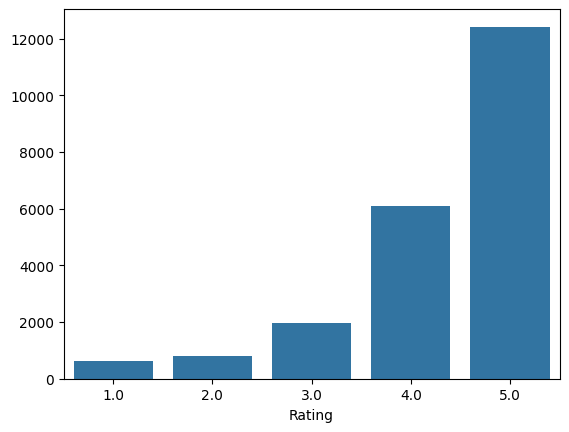

In [ ]:
# Visual showing the rating count per rating number
sb.barplot(x=df['Rating'].value_counts().index, y=df['Rating'].value_counts().values)
plt.show()

*Observation:* The rating '5.0' is the most popular rating in our dataset.

In [ ]:
# Check unique value count for each column
columns = df.columns
print(columns)

column_name_input = input("enter column name: ")

if column_name_input in columns:
  print (f"The number of unique values in column '{column_name_input}' is: {df[column_name_input].nunique()}")
else:
  print ("Column name is not identifiable")


Index(['userId', 'productId', 'Rating'], dtype='object')
enter column name: Rating
The number of unique values in column 'Rating' is: 5


In [ ]:
top_10_users = df['userId'].value_counts().head(10)
print(top_10_users)

userId
A5JLAU2ARJ0BO     520
ADLVFFE4VBT8      501
A3OXHLG6DIBRW8    498
A6FIAB28IS79      431
A680RUE1FDO8B     406
A1ODOGXEYECQQ8    380
A36K2N527TXXJN    314
A2AY4YUOX2N1BQ    311
AWPODHOB4GFWL     308
ARBKYIVNYWK3C     296
Name: count, dtype: int64


In [ ]:
# Checking the minimum and maximum count of ratings per user. The rating cutoff is 50 for the minimum value.
min = df['userId'].value_counts().min()
max = df['userId'].value_counts().max()

print("spectrum values of users: ", f"min: {min}, max: {max}")

spectrum values of users:  min: 150, max: 520


*Observation*: In our dataset the minimum ratings count is 150, as maintained from the rating_cutoff function, and our maximum ratings count is 520

## Model 1: Rank Based Recommendation

In [ ]:
# aggregating the average rating per poduct
avg_rating = df.groupby('productId')['Rating'].mean()
print("average rating per product is: ", avg_rating.mean())

average rating per product is:  4.282039825521485


In [ ]:
# Creating a new dataframe with the average rating per product along with the count of ratings per product
ratings_count = df.groupby('productId')['Rating'].count()
product_stats = pd.DataFrame({
    'AverageRating': avg_rating,
    'RatingCount': ratings_count
})

print(product_stats.head())

print()
print()

sorted_products_by_avg_rating = product_stats.sort_values(by='AverageRating', ascending=False)
display(sorted_products_by_avg_rating.head(5))

            AverageRating  RatingCount
productId                             
0970407998            4.0            1
0972683275            5.0            1
1400532655            1.0            1
1400699169            5.0            1
8862936826            2.0            1




,AverageRating,RatingCount
productId,,
B00LKG1MC8,5.0,1
B001NTFATI,5.0,2
B001NTBVPA,5.0,1
B008R6OPJQ,5.0,4
B001NS828K,5.0,2


In [ ]:
# Defining a function to retrieve the top (n) products based on the highest average rating and minimum interactions

def top_n_products(df, n, min_interactions=150):

    recommendations = df[df['RatingCount'] > min_interactions]

    recommendations = recommendations.sort_values(by='AverageRating', ascending=False)

    return recommendations.index[:n]


In [ ]:
# Top 5 products, averaged, with min 150 interactions
top_products = top_n_products(product_stats, n=150)
print("Top 5 products by average rating with minimum 150 interactions:")
print(top_products)
print()
top_products_info = product_stats.loc[top_products, ['AverageRating']]
print(top_products_info)

Top 5 products by average rating with minimum 150 interactions:
Index([], dtype='object', name='productId')

Empty DataFrame
Columns: [AverageRating]
Index: []


In [ ]:
# Top 10 products, averaged, with min 150 interactions
def top_n_products(df, n, min_interactions=150):

    recommendations = df[df['RatingCount'] > min_interactions]

    recommendations = recommendations.sort_values(by='AverageRating', ascending=False)

    return recommendations.index[:n]

top_products = top_n_products(product_stats, n=150)
print("Top 10 products by average rating with minimum 150 interactions:")
print(top_products)

Top 10 products by average rating with minimum 150 interactions:
Index([], dtype='object', name='productId')


## Model 2: Collaborative Filtering Recommendation System


In [ ]:
# To compute the accuracy of models
from surprise import accuracy

# Class is used to parse a file containing ratings, data should be in structure - user ; item ; rating
from surprise.reader import Reader

# Class for loading datasets
from surprise.dataset import Dataset

# For tuning model hyperparameters
from surprise.model_selection import GridSearchCV

# For splitting the rating data in train and test datasets
from surprise.model_selection import train_test_split

# For implementing similarity-based recommendation system
from surprise.prediction_algorithms.knns import KNNBasic

# For implementing matrix factorization based recommendation system
from surprise.prediction_algorithms.matrix_factorization import SVD

# for implementing K-Fold cross-validation
from surprise.model_selection import KFold

# For implementing clustering-based recommendation system
from surprise import CoClustering

In [ ]:
def precision_recall_at_k(model, k = 10, threshold = 3.5):
    """Return precision and recall at k metrics for each user"""

    # First map the predictions to each user
    user_est_true = defaultdict(list)

    predictions = model.test(testset)

    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():

        # Sort user ratings by estimated value
        user_ratings.sort(key = lambda x: x[0], reverse = True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(((true_r >= threshold) and (est >= threshold))
                              for (est, true_r) in user_ratings[:k])

        # Precision@K: Proportion of recommended items that are relevant
        # When n_rec_k is 0, Precision is undefined. Therefore, we are setting Precision to 0 when n_rec_k is 0

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        # When n_rel is 0, Recall is undefined. Therefore, we are setting Recall to 0 when n_rel is 0

        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    # Mean of all the predicted precisions are calculated.
    precision = round((sum(prec for prec in precisions.values()) / len(precisions)), 3)

    # Mean of all the predicted recalls are calculated.
    recall = round((sum(rec for rec in recalls.values()) / len(recalls)), 3)

    accuracy.rmse(predictions)

    print('Precision: ', precision) # Command to print the overall precision

    print('Recall: ', recall) # Command to print the overall recall

    print('F_1 score: ', round((2*precision*recall)/(precision+recall), 3)) # Formula to compute the F-1 score

In [ ]:
# Load the data reader, load the data, split the data into training/testing sets
reader = Reader(rating_scale=(0, 5))

data = Dataset.load_from_df(df[['userId', 'productId', 'Rating']], reader)

trainset, testset = train_test_split(data, test_size=0.40, random_state=42)

In [ ]:
# Creating the User-User based collaborative filtering model using the K-Nearest neighbors algorithm
from collections import defaultdict
sim_options = {'name': 'cosine',
               'user_based': True}

sim_user_user = KNNBasic(sim_options=sim_options, verbose=False, random_state=1)

sim_user_user.fit(trainset)

precision_recall_at_k(sim_user_user)

RMSE: 1.0322
Precision:  0.897
Recall:  0.132
F_1 score:  0.23


In [ ]:
# Initializing the model (or as some say, "Takeoff!")
userID_1 = 'A2NYK9KWFMJV4Y'
productID_1 = 'B00LA6T0LS'
Rating = df['Rating'].value_counts().count()

prediction = sim_user_user.predict(userID_1, productID_1)

# You can access the predicted rating using .est attribute
print(f"Predicted rating for User {userID_1} concerning Product {productID_1} is: {prediction.est}")

Predicted rating for User A2NYK9KWFMJV4Y concerning Product B00LA6T0LS is: 4.0


In [ ]:
def has_interacted(dataframe, user_id_to_check, product_id_to_check):
    # Filter the DataFrame for the specific user and product
    interaction = dataframe[(dataframe['userId'] == user_id_to_check) &
                              (dataframe['productId'] == product_id_to_check)]

    # If an interaction exists, return the rating; otherwise, return None
    if not interaction.empty:
        return f"This User has interacted with the product and given it a rating of: {interaction['Rating'].iloc[0]}"
    else:
        return f"User has not interacted with the product"


In [ ]:
has_interacted(df, userID_1, productID_1)

'This User has interacted with the product and given it a rating of: 4.0'

In [ ]:
# Initializing the model on another user who has not seen the product
userID_2 = 'A1EVV74UQYVKRY '
# productID_1 is the same as above
Rating = df['Rating'].value_counts().count()

prediction = sim_user_user.predict(userID_2, productID_1)

print(f"Predicted rating for User {userID_2} concerning Product {productID_1} is: {prediction.est}")

Predicted rating for User A1EVV74UQYVKRY  concerning Product B00LA6T0LS is: 4.3167880995749845


In [ ]:
has_interacted(df, userID_2, productID_1)

'User has not interacted with the product'

*Oservation:* The model has correctly predicted User_1s rating of Product_1

In [ ]:
# Get all unique user IDs that have interacted with the specific productID
productID_to_check = productID_1

interacting_users = df[df['productId'] == productID_to_check]['userId'].unique()

# Get all unique user IDs in the entire dataset
all_users = df['userId'].unique()

# Find user IDs that are in 'all_users' but not in 'interacting_users'
non_interacting_users = [user for user in all_users if user not in interacting_users]

print(f"Users who have NOT interacted with Product {productID_to_check}:")
print(non_interacting_users[:10]) # Displaying the first 10 to keep the output concise
print(f"Total number of users who have NOT interacted: {len(non_interacting_users)}")

Users who have NOT interacted with Product B00LA6T0LS:
['A17HMM1M7T9PJ1', 'A3TAS1AG6FMBQW', 'A5JLAU2ARJ0BO', 'A3PD8JD9L4WEII', 'A1ZU55TM45Y2R8', 'A1VQHH85U7PX0', 'A36K2N527TXXJN', 'ADLVFFE4VBT8', 'A250AXLRBVYKB4', 'A18HE80910BTZI']
Total number of users who have NOT interacted: 97


## Tuning the hyperparamters of the user-user similarity recommendation system





In [ ]:
# Hyperparameter tuning for the user-user similarity based model
param_grid = {'k': [40], 'min_k': [1],
              'sim_options': {'name': ['cosine'],
                              'user_based': [True], 'min_support':[4]}
              }

gs = GridSearchCV(KNNBasic, param_grid, measures=['rmse'], cv=3, n_jobs=-1)

gs.fit(data)

print(gs.best_score['rmse'])

print(gs.best_params['rmse'])

1.0097114569143981
{'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True, 'min_support': 4}}


In [ ]:
# Retrieve the best parameters from GridSearchCV
best_params = gs.best_params['rmse']

# Extract k and sim_options from the best parameters
best_k = best_params['k']
best_sim_options = best_params['sim_options']

# Initialize KNNBasic with the optimal parameters
sim_user_user_tuned = KNNBasic(k=best_k, sim_options=best_sim_options, verbose=False, random_state=1)

# Train the model on the training data
sim_user_user_tuned.fit(trainset)

# Evaluate the tuned model
precision_recall_at_k(sim_user_user_tuned)

RMSE: 1.0247
Precision:  0.872
Recall:  0.126
F_1 score:  0.22


In [ ]:
# Computing our model with k=10
sim_user_user_tuned = KNNBasic(k=10, sim_options=best_sim_options, verbose=False, random_state=1)

sim_user_user_tuned.fit(trainset)

precision_recall_at_k(sim_user_user_tuned)

RMSE: 1.0247
Precision:  0.872
Recall:  0.126
F_1 score:  0.22


*Observation:* Our model works identically with k = 10 or 40


In [ ]:
# Predict the rating for a specific user and product using the tuned model
prediction1 = sim_user_user_tuned.predict(userID_1, productID_1)
prediction2 = sim_user_user_tuned.predict(userID_2, productID_1)

print(f"Predicted rating for User {userID_1} concerning Product {productID_1} is: {prediction1.est}")
print(f"Predicted rating for User {userID_2} concerning Product {productID_1} is: {prediction2.est}")

Predicted rating for User A2NYK9KWFMJV4Y concerning Product B00LA6T0LS is: 4.0
Predicted rating for User A1EVV74UQYVKRY  concerning Product B00LA6T0LS is: 4.3167880995749845


*Observation*: After hypertuning our model, the prediction for user_1s rating of product_1 is still accurate.

## Implementing the recommendation algorithm based on optimized KNNBasic model

In [ ]:
def get_recommendations(data, userId, top_n, algo):

    # Creating an empty list to store the recommended product ids
    recommendations = []

    # Creating an user item interactions matrix
    user_item_interactions_matrix = data.pivot(index = 'userId', columns = 'productId', values = 'Rating')

    # Extracting those product ids which the userId has not interacted yet
    non_interacted_products = user_item_interactions_matrix.loc[userId][user_item_interactions_matrix.loc[userId].isnull()].index.tolist()

    # Looping through each of the product ids which userId has not interacted yet
    for item_id in non_interacted_products:

        # Predicting the ratings for those non interacted product ids by this user
        est = algo.predict(userId, item_id).est

        # Appending the predicted ratings
        recommendations.append((item_id, est))

    # Sorting the predicted ratings in descending order
    recommendations.sort(key = lambda x: x[1], reverse = True)

    return recommendations[:top_n] # Returing top n highest predicted rating products for this user

In [ ]:
df_recs = get_recommendations(df, userID_1 , 5, sim_user_user_tuned)
print(df_recs)

[('9800359788', 5), ('B00004TJ0X', 5), ('B00004TWM6', 5), ('B00004WLJ9', 5), ('B00004X109', 5)]


*Observation*: Our model has recommended products that are all rated similarly, but rated 1 point above Product_1.

## Item-Item Similarity-based Collaborative Filtering Recommendation System


In [ ]:
# Creating the Item-item based collaborative filtering model using the K-Nearest neighbors algorithm
sim_options = {'name': 'cosine',
               'user_based': False}

sim_item_item = KNNBasic(sim_options=sim_options, verbose=False, random_state=1)

sim_item_item.fit(trainset)

precision_recall_at_k(sim_item_item)

RMSE: 1.0030
Precision:  0.879
Recall:  0.128
F_1 score:  0.223


In [ ]:
# Predict the rating for a specific user and product using the tuned model
prediction1 = sim_item_item.predict(userID_1, productID_1)
prediction2 = sim_item_item.predict(userID_2, productID_1)

print(f"Predicted rating for User {userID_1} concerning Product {productID_1} is: {prediction1.est}")
print(f"Predicted rating for User {userID_2} concerning Product {productID_1} is: {prediction2.est}")


Predicted rating for User A2NYK9KWFMJV4Y concerning Product B00LA6T0LS is: 4.875
Predicted rating for User A1EVV74UQYVKRY  concerning Product B00LA6T0LS is: 4.3167880995749845


*Observation:* The item item similarity based model incorrectly predicted the rating given to product_1 by user_1.

## Hyperparameter tuning the item-item similarity-based model






In [ ]:
# Hyperparameter tuning for the item-item similarity based model
param_grid = {'k': [10,20,30], 'min_k': [3,6,9],
              'sim_options': {'name': ['msd','cosine'],
                              'user_based': [False], 'min_support':[4]}
              }

gs = GridSearchCV(KNNBasic, param_grid, measures=['rmse'], cv=3, n_jobs=-1)

gs.fit(data)

print(gs.best_score['rmse'])

print(gs.best_params['rmse'])

0.9830835831143752
{'k': 10, 'min_k': 3, 'sim_options': {'name': 'msd', 'user_based': False, 'min_support': 4}}


In [ ]:
# Retrieve the best parameters from GridSearchCV
best_params = gs.best_params['rmse']

# Extract k and sim_options from the best parameters
best_k = best_params['k']
best_sim_options = best_params['sim_options']

# Initialize KNNBasic with the optimal parameters
sim_item_item_tuned = KNNBasic(k=best_k, sim_options=best_sim_options, verbose=False, random_state=1)

# Train the model on the training data
sim_item_item_tuned.fit(trainset)

# Evaluate the tuned model
precision_recall_at_k(sim_item_item_tuned)

RMSE: 0.9988
Precision:  0.832
Recall:  0.12
F_1 score:  0.21


In [ ]:
# Predict the rating for a specific user and product using the tuned model
prediction1 = sim_user_user_tuned.predict(userID_1, productID_1)
prediction2 = sim_user_user_tuned.predict(userID_2, productID_1)

print(f"Predicted rating for User {userID_1} concerning Product {productID_1} is: {prediction1.est}")
print(f"Predicted rating for User {userID_2} concerning Product {productID_1} is: {prediction2.est}")


Predicted rating for User A2NYK9KWFMJV4Y concerning Product B00LA6T0LS is: 4.0
Predicted rating for User A1EVV74UQYVKRY  concerning Product B00LA6T0LS is: 4.3167880995749845


*Observation:* The item-item based similarity model correctly predicted User_1s rating of Product_1.

In [ ]:
# Highlighting 5 most similar users to user with internal id ==0
# Create an item-based KNNBasic model with 'msd' similarity
sim_options_item_item = {
    'name': 'msd',
    'user_based': False  # This makes it an item-item similarity model
}

sim_item_item_tuned = KNNBasic(sim_options=sim_options_item_item, verbose=False, random_state=1)

# Fit the model to the trainset
sim_item_item_tuned.fit(trainset)

# Get the raw product ID for internal item ID 0
raw_item_id_0 = trainset.to_raw_iid(0)

print(f"Raw product ID for internal item ID 0: {raw_item_id_0}")

# Get the internal item ID of the target product (raw_item_id_0)
target_item_inner_id = sim_item_item_tuned.trainset.to_inner_iid(raw_item_id_0)

# Get the 5 most similar items to the target item
# The get_neighbors method takes an inner id and returns a list of inner ids
similar_items_inner_ids = sim_item_item_tuned.get_neighbors(target_item_inner_id, k=5)

# Convert the inner IDs of similar items back to raw product IDs
similar_items_raw_ids = [sim_item_item_tuned.trainset.to_raw_iid(inner_id) for inner_id in similar_items_inner_ids]

print(f"Top 5 similar items to product {raw_item_id_0} (internal ID 0):")
for i, product_id in enumerate(similar_items_raw_ids):
    print(f"{i+1}. {product_id}")


Raw product ID for internal item ID 0: B00F3F0EIU
Top 5 similar items to product B00F3F0EIU (internal ID 0):
1. B007M50PTM
2. B0043T7FXE
3. B00BOHNYTW
4. B00829TIEK
5. B0041Q38NU


In [ ]:
get_recommendations(df, userID_1 , 5, sim_item_item_tuned)

[('1400699169', 5),
 ('9981719005', 5),
 ('B00000J061', 5),
 ('B00000J08Q', 5),
 ('B00000J1QS', 5)]

## Model 3: Model-Based Collaborative Filtering - Matrix Factorization

In [ ]:
# Use SVD matrix factorization. Use random_state = 1
svd_algo = SVD(random_state=1)

# Training the algorithm on the trainset
svd_algo.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd_algo)

RMSE: 0.9219
Precision:  0.892
Recall:  0.129
F_1 score:  0.225


In [ ]:
# Predict the rating for a specific user and product using the SVD algorithm
prediction1 = svd_algo.predict(userID_1, productID_1)
prediction2 = svd_algo.predict(userID_2, productID_1)

print(f"Predicted rating for User {userID_1} concerning Product {productID_1} is: {prediction1.est}")
print(f"Predicted rating for User {userID_2} concerning Product {productID_1} is: {prediction2.est}")


Predicted rating for User A2NYK9KWFMJV4Y concerning Product B00LA6T0LS is: 4.726443320280303
Predicted rating for User A1EVV74UQYVKRY  concerning Product B00LA6T0LS is: 4.238987714248966


In [ ]:
# Set the parameter space to tune
param_grid_svd = {'n_epochs': [20, 30],
                  'lr_all': [0.005, 0.002],
                  'reg_all': [0.02, 0.04]}

# Performing 3-fold gridsearch cross-validation
gs_svd = GridSearchCV(SVD, param_grid_svd, measures=['rmse'], cv=3, n_jobs=-1)

gs_svd.fit(data)

# Best RMSE score
print('Best RMSE score:', gs_svd.best_score['rmse'])

# Combination of parameters that gave the best RMSE score
print('Best parameters:', gs_svd.best_params['rmse'])

Best RMSE score: 0.9125446795510525
Best parameters: {'n_epochs': 20, 'lr_all': 0.005, 'reg_all': 0.04}


In [ ]:
# Retrieve the best parameters from GridSearchCV for SVD
best_params_svd = gs_svd.best_params['rmse']

# Initialize SVD with the optimal parameters
svd_algo_optimized = SVD(n_epochs=best_params_svd['n_epochs'], lr_all=best_params_svd['lr_all'], reg_all=best_params_svd['reg_all'], random_state=1)

# Train the algorithm on the trainset
svd_algo_optimized.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd_algo_optimized)

RMSE: 0.9206
Precision:  0.894
Recall:  0.13
F_1 score:  0.227


In [ ]:
# Predict the rating for a specific user and product using the optimized SVD algorithm
prediction1 = svd_algo_optimized.predict(userID_1, productID_1)
prediction2 = svd_algo_optimized.predict(userID_2, productID_1)

print(f"Predicted rating for User {userID_1} concerning Product {productID_1} is: {prediction1.est}")
print(f"Predicted rating for User {userID_2} concerning Product {productID_1} is: {prediction2.est}")


Predicted rating for User A2NYK9KWFMJV4Y concerning Product B00LA6T0LS is: 4.7271953200108685
Predicted rating for User A1EVV74UQYVKRY  concerning Product B00LA6T0LS is: 4.239810532152862


*Observation:* The Matrix Factorization algorithm incorrectly predicted User_1s rating of Product_1.

# **Conclusion:**


*   With a medium sized dataset we build 4 different recommendation system models in hopes of implementing them to improve customer experience and user customization
*   The model that performed the best was the tuned Item-Item similarity recommendation system
*   The model that performed the worst was the **Singular Value Decomposition** Matrix Factorization model





# **Recommendation:**

*   If I was a data science manager at Amazon building these models for relevant and stocked products I would use the tuned item-item recommendation system to recommend products to customers and improve our shopping experience.
*   Another model I would use to enrich the user experience is the User-user recommendation system model. Although this model didn't perform the BEST, it still performed well so I would consider using it as a **secondary** recommendation systems model.



In [ ]:
notebook_name = "/Recommendation_Systems_N_Ort.ipynb" # Replace with the actual name of your notebook
!jupyter nbconvert --to html "{notebook_name}"

[NbConvertApp] Converting notebook /Recommendation_Systems_N_Ort.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 446102 bytes to /Recommendation_Systems_N_Ort.html
